<a href="https://colab.research.google.com/github/contre55/ie332-project-group-/blob/main/A2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI
I have used ChatGPT to check how to sort the zones alphabetically in part b of Question 1 and how to turn the grouped index "zone" back into a regular column in part a of Question 2; reset_index(). I also used AI to help me get rid of "zone" word column in Q1 part b by using drop, so that way there are no issues with converting the string to numbers later on.

I used AI to check that my writing was concise and straightforward so that my ideas in Part B of this assignment were clear to the graders. I also used AI to check that my results were feasible and logical for the assignment given. This told me that I needed to change my approach for rounding so that the final result was given to 6 decimal places even when the result ends in a 0.

I used AI in Q4 before starting the problem to better understand how decision trees work. I also used AI to help write the code for creating graphs. This helped me better understand decision trees and how to visualize the results.

# Part A

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

if not Path("nba_shots.csv").is_file():
    raise FileNotFoundError("Upload nba_shots.csv to Colab's Files panel, then rerun this cell.")

shots = pd.read_csv("nba_shots.csv")

print("Dataset shape:", shots.shape)
display(shots.head())

Dataset shape: (20000, 11)


,shot_id,player,period,shot_clock,dist_ft,defender_ft,zone,catch_and_shoot,is_home,points,made
0,1,Vince Okafor,1,14.1,28.6,8.1,abovebreak3,0,1,3,1
1,2,Drew Hollis,4,13.2,29.7,3.0,abovebreak3,0,0,0,0
2,3,Jamal Price,3,12.5,3.1,6.2,restricted,0,0,2,1
3,4,Rex Dunn,2,14.4,25.6,6.5,abovebreak3,1,0,3,1
4,5,Devon Reyes,3,14.5,23.6,2.2,corner3,1,1,3,1


# Question 1
a.

The goal is to predict whether the player will score according to factors like the zone they shoot from, their distance to the basket, and their distance to the nearest opposing player. Because the model is predicting whether the player will make or miss, this is a binary choice, hence this is a classification problem.

Using "points" as an input is not appropriate as it results in data leakage because "points" data are recorded after the shot so they reveal the outcome. This means that the model does not actually learn how to predict and just looks up the answer that it is already fed, which results in a very high validation score that is misleading and inaccurate.

b.

In [2]:
# Distance only table
X_distance = shots[["dist_ft"]].copy()

# Full features
full_features = ["dist_ft", "defender_ft", "shot_clock", "period", "catch_and_shoot", "is_home", "zone"]

# One-hot zone encoding
X_zone = pd.get_dummies(shots["zone"], prefix="zone", dtype=int)

# Aphabetical order
X_full = pd.concat([shots[full_features].drop(columns="zone"), X_zone.sort_index(axis=1)], axis=1)

y = shots["made"]

print("Distance-only feature table")
print("Shape:", X_distance.shape)
print("Columns:", X_distance.columns.tolist())
display(X_distance)

print("\nFull feature table")
print("Shape:", X_full.shape)
print("Columns:", X_full.columns.tolist())
display(X_full)

print("\nTarget")
display(y)


Distance-only feature table
Shape: (20000, 1)
Columns: ['dist_ft']


,dist_ft
0,28.6
1,29.7
2,3.1
3,25.6
4,23.6
...,...
19995,2.9
19996,1.7
19997,3.2
19998,18.0



Full feature table
Shape: (20000, 11)
Columns: ['dist_ft', 'defender_ft', 'shot_clock', 'period', 'catch_and_shoot', 'is_home', 'zone_abovebreak3', 'zone_corner3', 'zone_midrange', 'zone_paint', 'zone_restricted']


,dist_ft,defender_ft,shot_clock,period,catch_and_shoot,is_home,zone_abovebreak3,zone_corner3,zone_midrange,zone_paint,zone_restricted
0,28.6,8.1,14.1,1,0,1,1,0,0,0,0
1,29.7,3.0,13.2,4,0,0,1,0,0,0,0
2,3.1,6.2,12.5,3,0,0,0,0,0,0,1
3,25.6,6.5,14.4,2,1,0,1,0,0,0,0
4,23.6,2.2,14.5,3,1,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
19995,2.9,3.6,7.6,3,0,1,0,0,0,0,1
19996,1.7,6.0,6.6,1,1,1,0,0,0,0,1
19997,3.2,2.0,10.7,2,0,0,0,0,0,0,1
19998,18.0,4.8,12.2,4,0,0,0,0,1,0,0



Target


,made
0,1
1,0
2,1
3,1
4,1
...,...
19995,1
19996,1
19997,1
19998,0


For the distance only feature table, each row shows one shot, and the column "dist_ft" shows the corresponding distance of the shooter from the basket in feet. For the full table, similarly, each row shows one shot, and the columns show the "circumstances" of that shot: the column "dist_ft" shows the corresponding distance of the shooter from the basket in feet; "defender_ft" shows the distance from the shooter to the nearest opposing player in feet; and "is_home" shows whether the shooter's team is playing at its own or at the opponent's venue. The full second table shows more information about each shot and contains the six non-zone predictors and five one-hot encoded zone indicators. Each zone indicator is 1 if a shot belongs to that zone and 0 otherwise. All five zone categories are retained, and the zone columns are arranged in alphabetical order after the numeric predictors. The target y is made, which indicates whether each shot was successful.

c.

In [3]:

train, test = train_test_split(shots, test_size=0.25, random_state=332)

# Distance only table
X_dist_train, y_dist_train = X_distance.loc[train.index], train["made"]
X_dist_test, y_dist_test = X_distance.loc[test.index], test["made"]

# Full table
X_full_train, y_full_train = X_full.loc[train.index], train["made"]
X_full_test, y_full_test = X_full.loc[test.index], test["made"]

print("Distance only table rows (training, test):", len(X_dist_train), len(X_dist_test))
print("Shape:", X_dist_train.shape)
print("Columns:", X_dist_train.columns.tolist())

print("\nFull table rows (training, test):", len(X_full_train), len(X_full_test))
print("Shape:", X_full_train.shape)
print("Columns:", X_full_train.columns.tolist())

Distance only table rows (training, test): 15000 5000
Shape: (15000, 1)
Columns: ['dist_ft']

Full table rows (training, test): 15000 5000
Shape: (15000, 11)
Columns: ['dist_ft', 'defender_ft', 'shot_clock', 'period', 'catch_and_shoot', 'is_home', 'zone_abovebreak3', 'zone_corner3', 'zone_midrange', 'zone_paint', 'zone_restricted']


# Question 2

a

,zone,n_shots,make_rate
4,restricted,4476,0.673369
3,paint,3185,0.525903
1,corner3,1502,0.421438
2,midrange,2569,0.382639
0,abovebreak3,3268,0.337515


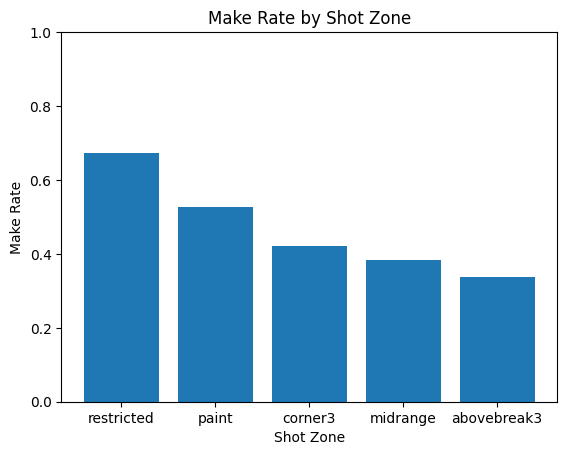

In [4]:
zone_summary = train.groupby("zone").agg(
    n_shots=("made", "count"),
    make_rate=("made", "mean")
).reset_index()

zone_summary = zone_summary.sort_values("make_rate", ascending=False)
display(zone_summary)

# Graphing
plt.bar(zone_summary["zone"], zone_summary["make_rate"])
plt.xlabel("Shot Zone")
plt.ylabel("Make Rate")
plt.title("Make Rate by Shot Zone")
plt.ylim(0, 1)
plt.show()

b

In [5]:
three_point_shots = train[train["zone"].isin(["corner3", "abovebreak3"])].copy()
three_point_shots["open_shot"] = three_point_shots["defender_ft"] >= 6
open_summary = three_point_shots.groupby("open_shot").agg(
    n_shots=("made", "count"),
    make_rate=("made", "mean")
).reset_index()

display(open_summary)


,open_shot,n_shots,make_rate
0,False,3725,0.320000
1,True,1045,0.520574


# Part B

**Question 3a**

A smaller C means stronger regularization because C is the inverse of regularization strength. I expect C = 0.001 to produce a smaller sum of squared coefficients than C = 100 because it penalizes large coefficients more strongly.

**Question 3b**

In [6]:
import numpy as np
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

# Define models
baseline = DummyClassifier(strategy="most_frequent")
lr1 = LogisticRegression(C=1, max_iter=2000)
lr2 = LogisticRegression(C=0.001, max_iter=2000)
lr3 = LogisticRegression(C=1, max_iter=2000)
lr4 = LogisticRegression(C=100, max_iter=2000)

# Five-fold cross-validation on training data
scores_b = cross_val_score(
    baseline, X_full_train, y_full_train, cv=5, scoring="accuracy"
)
scores_lr1 = cross_val_score(
    lr1, X_dist_train, y_dist_train, cv=5, scoring="accuracy"
)
scores_lr2 = cross_val_score(
    lr2, X_full_train, y_full_train, cv=5, scoring="accuracy"
)
scores_lr3 = cross_val_score(
    lr3, X_full_train, y_full_train, cv=5, scoring="accuracy"
)
scores_lr4 = cross_val_score(
    lr4, X_full_train, y_full_train, cv=5, scoring="accuracy"
)

# Fit logistic models on the entire training set
lr1.fit(X_dist_train, y_dist_train)
lr2.fit(X_full_train, y_full_train)
lr3.fit(X_full_train, y_full_train)
lr4.fit(X_full_train, y_full_train)

# Comparison table
comparison_q3 = pd.DataFrame({
    "ID": ["B", "LR1", "LR2", "LR3", "LR4"],
    "features": ["Full", "Distance only", "Full", "Full", "Full"],
    "C": ["-", 1, 0.001, 1, 100],
    "cv_mean": [
        scores_b.mean(),
        scores_lr1.mean(),
        scores_lr2.mean(),
        scores_lr3.mean(),
        scores_lr4.mean()
    ],
    "cv_sd": [
        scores_b.std(),
        scores_lr1.std(),
        scores_lr2.std(),
        scores_lr3.std(),
        scores_lr4.std()
    ],
    "sum_sq_coef": [
        "-",
        round(np.sum(lr1.coef_ ** 2), 6),
        round(np.sum(lr2.coef_ ** 2), 6),
        round(np.sum(lr3.coef_ ** 2), 6),
        round(np.sum(lr4.coef_ ** 2), 6)
    ]
})

display(comparison_q3.round(6))

accuracy_change = (scores_lr3.mean() - scores_lr1.mean()) * 100

print(
    "LR3 minus LR1:",
    round(accuracy_change, 6),
    "percentage points"
)

,ID,features,C,cv_mean,cv_sd,sum_sq_coef
0,B,Full,-,0.506133,0.000163,-
1,LR1,Distance only,1,0.618133,0.007705,0.002851
2,LR2,Full,0.001,0.625467,0.008471,0.050645
3,LR3,Full,1,0.630400,0.010500,1.214138
4,LR4,Full,100,0.630667,0.010319,1.251863


LR3 minus LR1: 1.226667 percentage points


(i) Moving from distance-only LR1 to full-feature LR3 increases mean CV accuracy by 1.23 percentage points, from about 61.81% to 63.04%. The additional features improve prediction compared with using distance alone.

(ii) LR2 has the smaller sum of squared coefficients: approximately 0.050645 compared with 1.251863 for LR4. This agrees with my prediction in part (a), since the smaller C applies stronger regularization.

(iii) LR2 has the smallest sum of squared coefficients, while LR4 has the highest mean CV accuracy. They are different models, so the strongest regularization does not give the highest validation accuracy in this comparison.

**Question 3c**

In [7]:
# Intercept and distance coefficient from LR1
a = lr1.intercept_[0]
b = lr1.coef_[0, 0]

print(f"Intercept: {a: .6f}")
print(f"Distance coefficient: {a: .6f}")

# Make probability at 18 feet using unrounded values
z = a + b * 18
p = 1 / (1 + np.exp(-z))

print("\na + b * 18:", round(z, 6))
print("Probability using formula:", round(p, 6))

# Compare with predict_proba
shot_18 = pd.DataFrame({"dist_ft": [18]})
p_predict = lr1.predict_proba(shot_18)[0, 1]

print("Probability using predict_proba:", round(p_predict, 6))

# Predicted class at each cutoff
if p >= 0.5:
    print("\nCutoff 0.5: Make (1)")
else:
    print("\nCutoff 0.5: Miss (0)")

if p >= 0.4:
    print("Cutoff 0.4: Make (1)")
else:
    print("Cutoff 0.4: Miss (0)")

Intercept:  0.701770
Distance coefficient:  0.701770

a + b * 18: -0.259253
Probability using formula: 0.435547
Probability using predict_proba: 0.435547

Cutoff 0.5: Miss (0)
Cutoff 0.4: Make (1)


The fitted intercept is 0.70177 and the distance coefficient is -0.05339. Using the unrounded coefficients, the predicted probability of making an 18-foot shot is approximately 0.435547, or 43.55%. The formula and predict_proba give the same probability. At a cutoff of 0.5, the predicted class is miss (0). At a cutoff of 0.4, the predicted class is make (1).

**Question 4a**

Setting min_samples_leaf = 50 means thats each leaf must contain at least 50 samples. Changing this value from 1 to 50 means that there will be less or the same number of leaves. This is because the tree cannot make as many splits. Thus, the training accuracy will also decrease or stay the same becasue the tree becomes less flexible.

**Question 4b**

In [8]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

tree_settings = [
    ("T1", 5, 1),
    ("T2", 5, 50),
    ("T3", None, 1),
    ("T4", None, 50)
]

tree_results = []

for tree_id, depth, leaf_size in tree_settings:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=leaf_size,
        random_state=332
    )

    # Fivefold cross validation
    scores = cross_val_score(
        tree, X_full_train, y_full_train,
        cv=5, scoring="accuracy"
    )

    # Fit it
    tree.fit(X_full_train, y_full_train)

    # add results
    tree_results.append({
        "ID": tree_id,
        "max_depth": depth,
        "min_samples_leaf": leaf_size,
        "n_leaves": tree.get_n_leaves(),
        "train_accuracy": tree.score(X_full_train, y_full_train),
        "cv_mean": scores.mean(),
        "cv_sd": scores.std()
    })

# Create table
comparison_q4 = pd.DataFrame(tree_results)

display(comparison_q4.round(3))


,ID,max_depth,min_samples_leaf,n_leaves,train_accuracy,cv_mean,cv_sd
0,T1,5.0,1,32,0.640,0.630,0.009
1,T2,5.0,50,32,0.640,0.631,0.013
2,T3,NaN,1,4900,1.000,0.547,0.009
3,T4,NaN,50,229,0.665,0.614,0.014


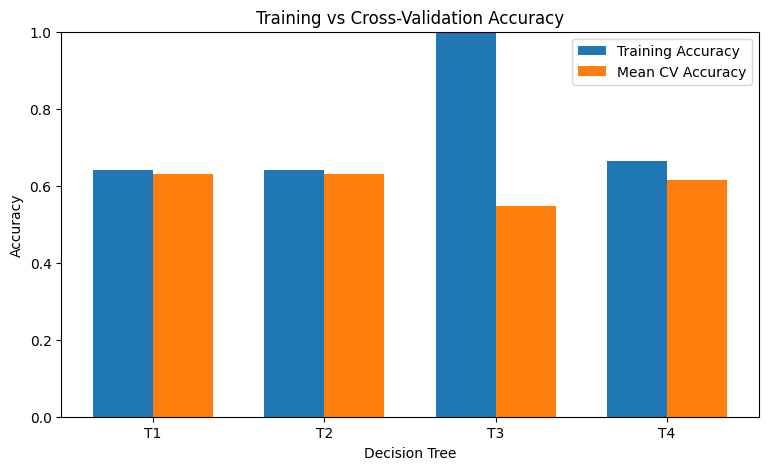

In [9]:

#training vs cv accuracy data
import numpy as np

x = np.arange(len(comparison_q4))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    comparison_q4["train_accuracy"],
    width,
    label="Training Accuracy"
)

plt.bar(
    x + width / 2,
    comparison_q4["cv_mean"],
    width,
    label="Mean CV Accuracy"
)

plt.xticks(x, comparison_q4["ID"])
plt.xlabel("Decision Tree")
plt.ylabel("Accuracy")
plt.title("Training vs Cross-Validation Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.show()


**Question 4c**

In [10]:

# comparing T1/T2 and T3/T4

for first, second in [("T1", "T2"), ("T3", "T4")]:
    a = comparison_q4.set_index("ID").loc[first]
    b = comparison_q4.set_index("ID").loc[second]

    print(f"{first} vs {second}")
    print("Leaves:", a["n_leaves"], "vs", b["n_leaves"])
    print("Training accuracy:",
          round(a["train_accuracy"], 3), "vs",
          round(b["train_accuracy"], 3))
    print("Mean CV accuracy:",
          round(a["cv_mean"], 3), "vs",
          round(b["cv_mean"], 3))
    print()

best_train = comparison_q4.loc[comparison_q4["train_accuracy"].idxmax(), "ID"]
best_cv = comparison_q4.loc[comparison_q4["cv_mean"].idxmax(), "ID"]

print("Highest training accuracy:", best_train)
print("Highest mean CV accuracy:", best_cv)


T1 vs T2
Leaves: 32.0 vs 32.0
Training accuracy: 0.64 vs 0.64
Mean CV accuracy: 0.63 vs 0.631

T3 vs T4
Leaves: 4900.0 vs 229.0
Training accuracy: 1.0 vs 0.665
Mean CV accuracy: 0.547 vs 0.614

Highest training accuracy: T3
Highest mean CV accuracy: T2


Comparing T1 and T2:
- both have 32 leaves
- nearly the same training accuracy of 0.640.

Comparing T3 and T4:
- the number of leaves decreases from 4900 to 229
- training accuracy decreases from 1.000 to 0.665.

This is what I expected as increasing the minimum leaf size makes the tree less complex.

Increasing min_samples_leaf slightly improves CV accuracy from 0.630 to 0.631 for T1 and T2, and improves it from 0.547 to 0.614 for T3 and T4.

T3 has the highest training accuracy. T2 has the highest mean CV accuracy. This demonstrates that a model can do very well on training data but worse on new data. This is due to overfitting.

**Question 4d**

In [11]:

# Adding T5

t5 = DecisionTreeClassifier(
    max_depth=1,
    min_samples_leaf=50,
    random_state=332
)

scores_t5 = cross_val_score(
    t5, X_full_train, y_full_train,
    cv=5, scoring="accuracy"
)

# Fit on training
t5.fit(X_full_train, y_full_train)

# add to existing table
t5_result = pd.DataFrame([{
    "ID": "T5",
    "max_depth": 1,
    "min_samples_leaf": 50,
    "n_leaves": t5.get_n_leaves(),
    "train_accuracy": t5.score(X_full_train, y_full_train),
    "cv_mean": scores_t5.mean(),
    "cv_sd": scores_t5.std()
}])

comparison_q4 = pd.concat(
    [comparison_q4, t5_result],
    ignore_index=True
)

display(comparison_q4.round(3))


,ID,max_depth,min_samples_leaf,n_leaves,train_accuracy,cv_mean,cv_sd
0,T1,5.0,1,32,0.640,0.630,0.009
1,T2,5.0,50,32,0.640,0.631,0.013
2,T3,NaN,1,4900,1.000,0.547,0.009
3,T4,NaN,50,229,0.665,0.614,0.014
4,T5,1.0,50,2,0.621,0.620,0.007


Training accuracy increases from 0.621 to 0.640 to 0.665, as we increase the allowed depth from 1 to 5 and no limit. However, we notice that the mean CV accuracy first increases from 0.620 to 0.631, but then decreases to 0.614. This is most likely because a very shallow tree may not learn enough from the data, while a very deep tree can overfit. Thus, in this case the best solution is a maximum depth of 5 because it gives the best validation accuracy among these three models.

**Question 4e**

In [12]:

# from q3
q3_models = pd.DataFrame({
    "ID": ["B", "LR1", "LR2", "LR3", "LR4"],
    "cv_mean": [
        scores_b.mean(),
        scores_lr1.mean(),
        scores_lr2.mean(),
        scores_lr3.mean(),
        scores_lr4.mean()
    ]
})

# from q4
q4_models = comparison_q4[["ID", "cv_mean"]]

# combine
all_models = pd.concat(
    [q3_models, q4_models],
    ignore_index=True
)

display(all_models.round(6))

best_id = all_models.loc[
    all_models["cv_mean"].idxmax(), "ID"
]

best_accuracy = all_models["cv_mean"].max()

print("Selected model:", best_id)
print("Mean CV accuracy:", f"{best_accuracy:.6f}")

# report
if best_id.startswith("T"):
    settings = comparison_q4.set_index("ID").loc[best_id]
    print("Model: DecisionTreeClassifier")
    print("Features: Full")
    print("max_depth:", settings["max_depth"])
    print("min_samples_leaf:", int(settings["min_samples_leaf"]))
    print("random_state: 332")


,ID,cv_mean
0,B,0.506133
1,LR1,0.618133
2,LR2,0.625467
3,LR3,0.630400
4,LR4,0.630667
5,T1,0.629600
6,T2,0.631133
7,T3,0.547133
8,T4,0.613933
9,T5,0.620067


Selected model: T2
Mean CV accuracy: 0.631133
Model: DecisionTreeClassifier
Features: Full
max_depth: 5.0
min_samples_leaf: 50
random_state: 332


The selected model is T2. It's a DecisionTreeClassifier using the full feature set, with max_depth=5, min_samples_leaf=50, and random_state=332. It has the highest mean CV accuracy of 0.631133.

**PART C**

Question 5a

In [13]:
from matplotlib import cm
from sklearn.metrics import accuracy_score, confusion_matrix

tree_q5 = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=50,
    random_state=332
)
tree_q5.fit(X_full_train, y_full_train)

y_pred_q5 = tree_q5.predict(X_full_test)

accuracy_q5 = accuracy_score(y_full_test, y_pred_q5)
print("Test Accuracy:", round(accuracy_q5, 3))

cm_q5 = confusion_matrix(y_full_test, y_pred_q5, labels=[0,1])

cm_df_q5 = pd.DataFrame(cm_q5,
    index=["Actual Miss (0)", "Actual Make(1)"],
    columns=["Predicted Miss (0)", "Predicted Make (1)"]
)

display(cm_df_q5)

Test Accuracy: 0.633


,Predicted Miss (0),Predicted Make (1)
Actual Miss (0),1794,736
Actual Make(1),1098,1372


Question 5b

In [14]:
TN, FP, FN, TP = cm_q5.ravel()

precision = TP / (TP + FP)
recall = TP / (TP + FN)

print("Precision calculations:", TP, "/", TP + FP)
print("Precision:", round(precision,3))

print("Recall calculation:", TP, "/", TP + FN)
print("Recall:", round(recall,3))

Precision calculations: 1372 / 2108
Precision: 0.651
Recall calculation: 1372 / 2470
Recall: 0.555


A false positive happens when the model predicts that a shot wll be made, but the shot is actually missed. A false negative happens whent the model predicts that a shot will be msised, but the shot is actually made.

Question 6a

In [15]:
TN = 598
FP = 53
FN = 207
TP = 46

total_attempts = TN + FP + FN + TP
actual_makes = FN + TP
actual_misses = TN + FP

print("Total attempts:", total_attempts)
print("Actual makes:", actual_makes)
print("Actual misses:", actual_misses)

model_accuracy = (TP + TN) / total_attempts
model_recall = TP / actual_makes

miss_accuracy = actual_misses / total_attempts
miss_recall = 0 / actual_makes

comparison = pd.DataFrame({
    "method" : ["Original Model", "Always Predict Miss"],
    "accuracy": [model_accuracy, miss_accuracy],
    "recall" : [model_recall, miss_recall]
})

display(comparison.round(3))

print("Model Accuracy:", TP + TN, "/", total_attempts)
print("Model Recall:", TP, "/", actual_makes)
print("Always miss accuracy:", actual_misses, "/", total_attempts)
print("Always miss recall:", 0, "/", actual_makes)

Total attempts: 904
Actual makes: 253
Actual misses: 651


,method,accuracy,recall
0,Original Model,0.712,0.182
1,Always Predict Miss,0.720,0.000


Model Accuracy: 644 / 904
Model Recall: 46 / 253
Always miss accuracy: 651 / 904
Always miss recall: 0 / 253


Question 6b

I do not agree. Even though prediciting a miss has a higher accuracy (0.72 vs 0.712), it has a recall of 0, which means it fails to identify any of the 253 actual makes. The original model has a recall of 0.182, correctly identifying 46/253 makes. Since there are more misses (651) than makes (253), always predicting a miss can achieve higher accuracy without identifying any made shots. So, a higher accuracy does not necessarily mean a model is better at identifying actual makes.